<img src = "https://drive.google.com/uc?export=view&id=1A9dhO0gYByNJf9ya0SZmeCzZIeepRhsO" alt = "Encabezado MLDS" width = "100%">  </img>

# **Modelamiento y Validación**
---

**Proyecto aplicado:** reconocimiento de gestos de la mano a partir de señales de electromiografía (EMG) de superficie, con validación **por sujeto** (generalización a personas no vistas).

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. MARINA ANTOLÍNEZ CABRERO
2. JORGE ESAU TIERRADENTRO CRUZ

## **1. Selección y diseño de modelos**
---

Seleccione el/los modelo/s a explorar para aplicar sobre el conjunto de datos. Recuerde que la selección del modelo está influenciada por diferentes factores.

Además, debe definir cuál es su problema:

- **Regresión**: se busca estimar un valor continúo a partir de los datos.
- **Clasificación**: permite estimar un valor categórico a partir de los datos.
- **Agrupamiento**: permite encontrar grupos de datos similares.
- **Otros modelos**: recuerde que dispone de otros tipos de tareas supervisadas y no supervisadas.

Justifique la selección y el diseño de los modelos a explorar.

### **1.1. Definición del problema**

**Tipo de problema: clasificación multiclase supervisada.** Cada ventana de 200 ms de EMG de superficie (8 canales, generada en la Fase 3) debe asignarse a uno de los gestos de la mano. Los demás tipos de tarea se descartan por las razones siguientes:

| Tipo de tarea | ¿Aplica? | Justificación |
|---|---|---|
| **Regresión** | No | La variable objetivo (`clase`) es categórica: no hay un valor continuo que estimar. |
| **Clasificación** | **Sí (tarea principal)** | Se dispone de etiquetas fiables para cada ventana y el objetivo del proyecto es reconocer el gesto. |
| **Agrupamiento** | Solo exploratorio | Con etiquetas disponibles no es la tarea adecuada, pero se usa PCA y el coeficiente de silueta para comprobar si la estructura de los datos la dominan los gestos o los sujetos. |
| **Otros** (detección de anomalías, aprendizaje profundo sobre series) | No | Los valores extremos son contracciones reales (Fase 3) y con ~10 mil ventanas de 25 lecturas el aprendizaje profundo tendría alto riesgo de sobreajuste. |

**Reto central: generalizar a sujetos no vistos.** La señal EMG cambia entre personas (anatomía, colocación de la pulsera, fuerza de contracción). Por eso todo el diseño experimental valida **por sujeto**: ningún sujeto aparece a la vez en entrenamiento y en prueba, porque las ventanas solapadas de una misma persona son casi copias entre sí y darían una estimación demasiado optimista.

### **1.2. Factores que influyen en la selección del modelo**

* **Tamaño de los datos:** ~10 mil ventanas y 40 características → problema pequeño-mediano, adecuado para modelos clásicos de aprendizaje automático, con entrenamiento rápido y búsqueda de hiperparámetros viable.
* **Dimensionalidad y tipo de variables:** características numéricas continuas con escalas muy distintas (RMS, MAV, WL frente a conteos como ZC o SSC) → los modelos basados en distancia o margen necesitan estandarización.
* **Variabilidad entre sujetos y ruido:** conviene que el modelo capture fronteras no lineales y tenga regularización ajustable.
* **Valores extremos conservados:** los árboles son robustos a ellos; los modelos de distancia o margen son más sensibles.
* **Balance de clases:** equilibradas tras excluir la clase 7 → macro-F1 como métrica principal y exactitud como complemento.
* **Interpretabilidad y coste de inferencia:** un reconocedor de gestos debe responder en tiempo real, así que se valoran modelos livianos y con importancia de características interpretable.

### **1.3. Modelos a explorar**

| Modelo | Rol en el estudio | Por qué se incluye | Hiperparámetros principales |
|---|---|---|---|
| **Dummy (clase más frecuente)** | Referencia mínima | Cualquier modelo útil debe superarlo. | — |
| **Regresión logística** | Línea base lineal e interpretable | Mide cuánto se gana con modelos no lineales. | `C` |
| **k-vecinos (kNN)** | Modelo basado en instancias | Sensible a la variabilidad entre sujetos; contrasta con los demás. | `n_neighbors`, `weights`, `p` |
| **SVM con núcleo RBF** | Candidato principal | Muy usado en reconocimiento de gestos EMG con características de dominio temporal. | `C`, `gamma` |
| **Random Forest** | Ensamble de árboles (bagging) | Robusto a atípicos, no requiere escalado y da importancia de características. | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| **Gradient Boosting (HistGradientBoosting)** | Ensamble de árboles (boosting) | Referente en datos tabulares; se contrasta con el bagging. | `learning_rate`, `max_iter`, `max_leaf_nodes`, `l2_regularization` |

**Modelos descartados:** las redes convolucionales 1D no se exploran porque cada ventana tiene solo 25 lecturas por canal y pocos miles de ejemplos por clase; el enfoque estándar en EMG con este volumen de datos son las características manuales y los clasificadores clásicos.

### **1.4. Diseño experimental**

Las decisiones que la Fase 3 dejó pendientes quedan resueltas así:

1. **Partición por sujeto:** ~20 % de los sujetos se reservan como conjunto de **prueba** (hold-out) y no se usan para elegir modelo ni hiperparámetros. En el 80 % restante se hace validación cruzada con `StratifiedGroupKFold` (5 particiones) agrupando por sujeto.
2. **Características por ventana:** 5 descriptores de dominio temporal por canal → 40 variables: **RMS**, **MAV**, **WL** (longitud de forma de onda), **ZC** (cruces por cero) y **SSC** (cambios de signo de la pendiente). Solo dominio temporal, porque la frecuencia efectiva (125–200 Hz, Fase 3) no permite características espectrales fiables.
3. **Normalización:** `StandardScaler` dentro del `Pipeline` (ajustado solo con el entrenamiento de cada partición, sin fuga de información). Además se prueba la normalización por sujeto como experimento (sección 4).
4. **Clase 7 (palma extendida):** **se excluye del modelo principal.** Solo existe en 2 de los 36 sujetos, por lo que con validación por sujeto no habría forma fiable de entrenarla y evaluarla, y tiene unas 100 ventanas frente a más de 1,600 en las demás clases.
Decidimos documentarlo como limitación y trabajo futuro, y en la sección 4 se estudia cómo reacciona el modelo ante ella. El problema final es un clasificador de **6 gestos**.
5. **Métricas:** macro-F1 (principal), exactitud, exactitud balanceada, AUC por clase y matriz de confusión.

## **2. Entrenamiento del Modelo y Selección de Hiperparámetros**
---

Entrene el modelo y consiga la combinación eficiente de hiperparámetros para obtener un rendimiento óptimo.

Es importante visualizar los resultados de manera clara y comprensible. Para esto, **se deben utilizar tablas y gráficos** que muestren cómo cambian las métricas de desempeño del proceso de entrenamiento en función de los hiperparámetros probados. Algunas herramientas visuales útiles incluyen las *curvas de aprendizaje* y las *curvas de validación,* que nos permiten comparar el rendimiento del modelo con diferentes ajustes de hiperparámetros.

### **2.1. Carga de datos y decisión sobre la clase 7**

Se cargan las ventanas de la Fase 3: tensor `X` de forma `(ventanas, 25 lecturas, 8 canales)`, etiqueta `y` y los metadatos `sujeto` y `archivo` (solo para agrupar, nunca como entrada del modelo).


In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (GroupShuffleSplit, StratifiedGroupKFold, LeaveOneGroupOut,
                                     GridSearchCV, RandomizedSearchCV, cross_validate,
                                     cross_val_predict, validation_curve, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, classification_report, ConfusionMatrixDisplay,
                             silhouette_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
canales = [f"canal_{i}" for i in range(1, 9)]
NOMBRES_GESTOS = {1: "Reposo", 2: "Puño cerrado", 3: "Flexión muñeca", 4: "Extensión muñeca",
                  5: "Desv. radial", 6: "Desv. cubital", 7: "Palma extendida"}

# Cargamos archivo fase3
RUTA = "ventanas_fase3.npz"
if os.path.exists(RUTA):
    d = np.load(RUTA, allow_pickle=False)
    X_ventanas, y_ventanas = d["X"], d["y"]
    sujetos_ventanas, archivos_ventanas = d["sujetos"], d["archivos"]
print("X:", X_ventanas.shape, "| y:", y_ventanas.shape)

# Mostarmos la presencia de cada clase por sujeto para justificar la decisión sobre la clase 7
presencia = (pd.crosstab(sujetos_ventanas, y_ventanas) > 0).sum(axis=0)
presencia.index = [f"{c} - {NOMBRES_GESTOS[c]}" for c in presencia.index]
print("\nSujetos que contienen cada clase:")
print(presencia.rename("sujetos").to_string())

# Excluimos de la clase 7 del modelo principal
CLASES_EXCLUIDAS = [7]
mascara = ~np.isin(y_ventanas, CLASES_EXCLUIDAS)
X_all, y_all = X_ventanas[mascara], y_ventanas[mascara]
g_all, arch_all = sujetos_ventanas[mascara], archivos_ventanas[mascara]
X_clase7 = X_ventanas[np.isin(y_ventanas, CLASES_EXCLUIDAS)]
clases = np.sort(np.unique(y_all))
print(f"\nVentanas tras excluir la clase 7: {len(y_all):,} | clases: {[int(c) for c in clases]} "
      f"| sujetos: {len(np.unique(g_all))}")

X: (10090, 25, 8) | y: (10090,)

Sujetos que contienen cada clase:
1 - Reposo              36
2 - Puño cerrado        36
3 - Flexión muñeca      36
4 - Extensión muñeca    36
5 - Desv. radial        36
6 - Desv. cubital       36
7 - Palma extendida      2

Ventanas tras excluir la clase 7: 9,990 | clases: [1, 2, 3, 4, 5, 6] | sujetos: 36


### **2.2. Exploración por sujeto y gesto**

Se examina cómo se distribuyen los datos por sujeto y por gesto, que es lo que condiciona el diseño de la validación y la elección de características.

**Muestras por sujeto y clase**

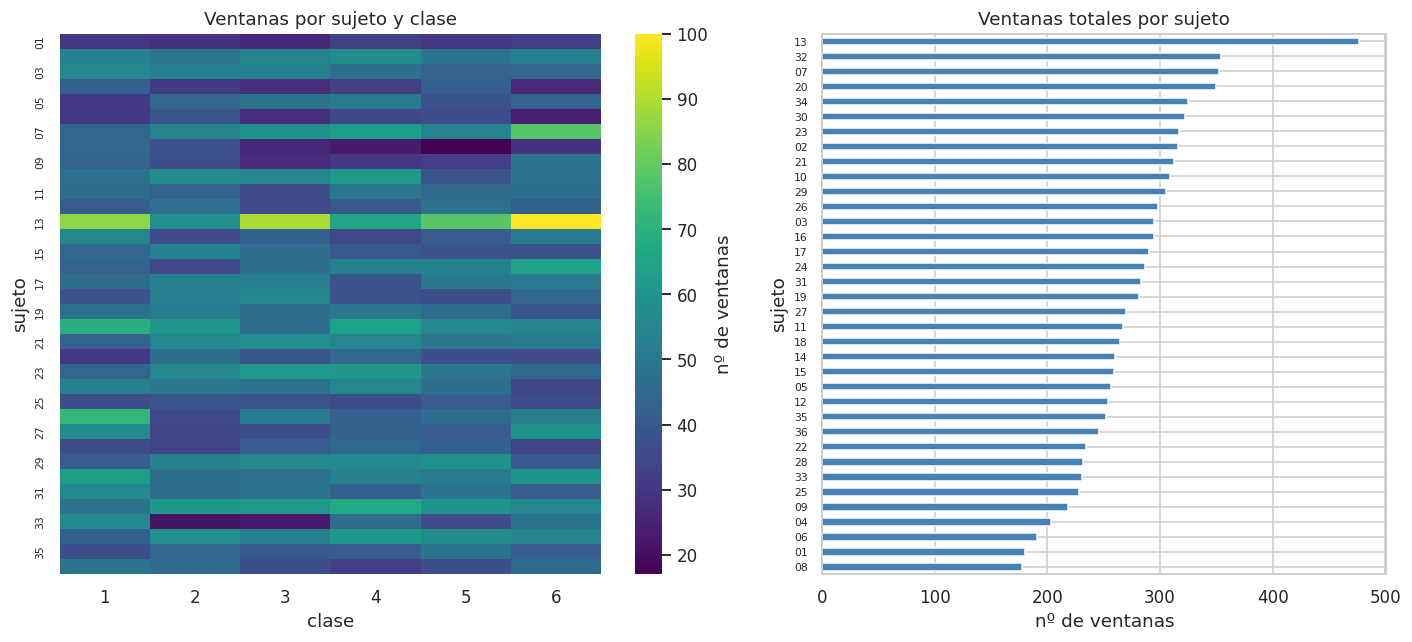

In [ ]:
tabla = pd.crosstab(pd.Series(g_all, name="sujeto"), pd.Series(y_all, name="clase"))
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(tabla, cmap="viridis", ax=ax[0], cbar_kws={"label": "nº de ventanas"})
ax[0].set_title("Ventanas por sujeto y clase"); ax[0].tick_params(axis="y", labelsize=7)
tabla.sum(axis=1).sort_values().plot.barh(ax=ax[1], color="steelblue")
ax[1].set_title("Ventanas totales por sujeto"); ax[1].set_xlabel("nº de ventanas")
ax[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

**Señales de ejemplo por gesto:** una ventana de 200 ms de un mismo sujeto para cada gesto, con los 8 canales y la misma escala vertical para comparar amplitudes.

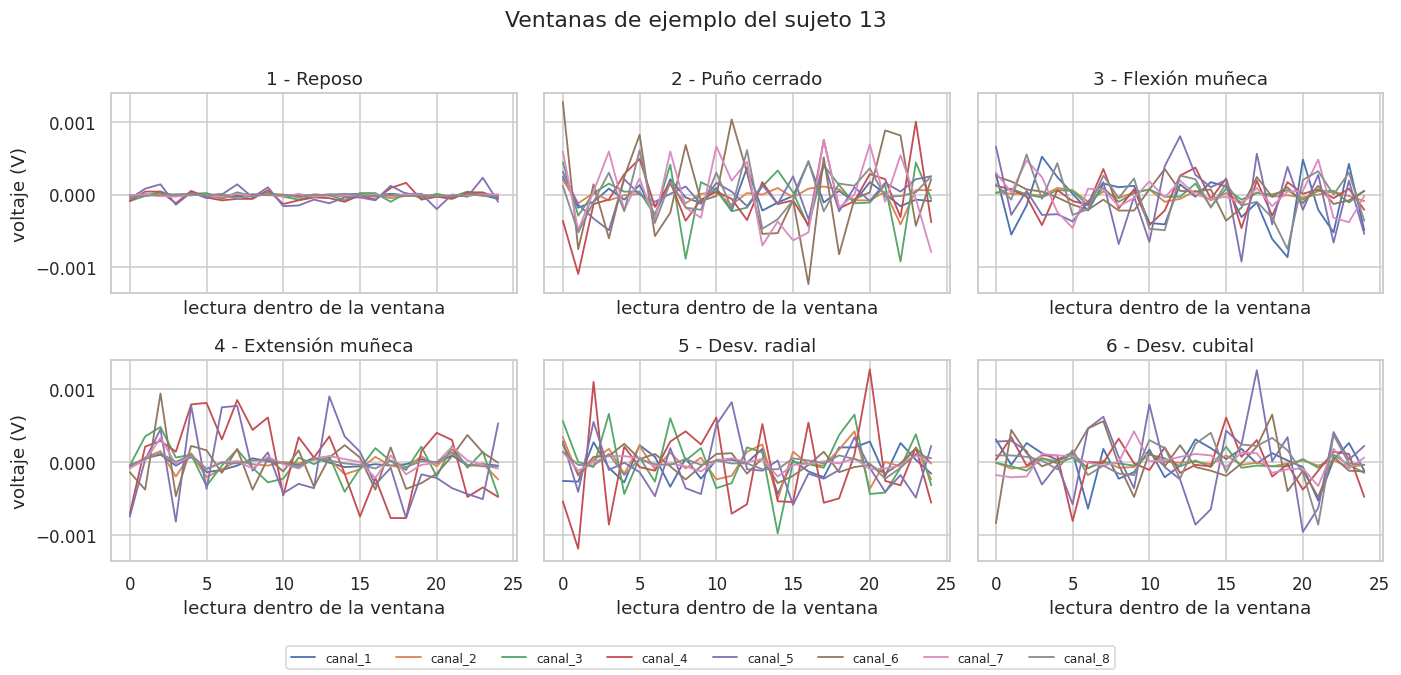

In [ ]:
suj_ej = pd.Series(g_all).value_counts().index[0]          # sujeto con más ventanas
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), clases):
    idx = np.where((g_all == suj_ej) & (y_all == c))[0][0]
    for k in range(8):
        ax.plot(X_all[idx][:, k], lw=1.2, label=canales[k] if c == clases[0] else None)
    ax.set_title(f"{c} - {NOMBRES_GESTOS[c]}"); ax.set_xlabel("lectura dentro de la ventana")
axes[0, 0].set_ylabel("voltaje (V)"); axes[1, 0].set_ylabel("voltaje (V)")
fig.legend(loc="lower center", ncol=8, fontsize=8)
fig.suptitle(f"Ventanas de ejemplo del sujeto {suj_ej}", y=1.0)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

### **2.3. Extracción de características**

Cada ventana `(25 lecturas × 8 canales)` se resume en **5 características de dominio temporal por canal → 40 variables**:

| Característica | Qué mide |
|---|---|
| **RMS** (raíz del valor cuadrático medio) | Nivel de activación muscular (energía de la señal). |
| **MAV** (valor absoluto medio) | Amplitud media de la contracción; robusta y muy usada en EMG. |
| **WL** (*waveform length*) | Complejidad y variación acumulada de la señal. |
| **ZC** (cruces por cero) | Estimación gruesa del contenido en frecuencia. |
| **SSC** (cambios de signo de la pendiente) | Complemento de ZC sobre frecuencia y forma de la señal. |

ZC y SSC usan un umbral de medio escalón de cuantización (5e-6 V) porque de esta manera, evitamos contar el ruido de la conversión a 8 bits como cruces reales.

In [ ]:
def extraer_caracteristicas(X, umbral=5e-6):
    # X: (n_ventanas, n_lecturas, n_canales) -> DataFrame (n_ventanas, 5 * n_canales)
    dif = np.diff(X, axis=1)
    rms = np.sqrt(np.mean(X ** 2, axis=1))
    mav = np.mean(np.abs(X), axis=1)
    wl = np.sum(np.abs(dif), axis=1)
    zc = np.sum((X[:, :-1] * X[:, 1:] < 0) & (np.abs(dif) >= umbral), axis=1)
    d1 = X[:, 1:-1] - X[:, :-2]
    d2 = X[:, 1:-1] - X[:, 2:]
    ssc = np.sum((d1 * d2 > 0) & (np.abs(d1) >= umbral) & (np.abs(d2) >= umbral), axis=1)
    bloques = {"RMS": rms, "MAV": mav, "WL": wl, "ZC": zc, "SSC": ssc}
    cols = {f"{nombre}_{c}": arr[:, i] for nombre, arr in bloques.items() for i, c in enumerate(canales)}
    return pd.DataFrame(cols).astype(float)

F_all = extraer_caracteristicas(X_all)
print("Matriz de características:", F_all.shape)
F_all.describe().T[["mean", "std", "min", "max"]].head(10)

Matriz de características: (9990, 40)


,mean,std,min,max
RMS_canal_1,0.000133,0.000137,0.000008,0.000925
RMS_canal_2,0.000093,0.000100,0.000011,0.000790
RMS_canal_3,0.000103,0.000087,0.000011,0.000779
RMS_canal_4,0.000201,0.000174,0.000011,0.000872
RMS_canal_5,0.000253,0.000191,0.000011,0.000880
RMS_canal_6,0.000194,0.000154,0.000009,0.000815
RMS_canal_7,0.000126,0.000120,0.000010,0.000825
RMS_canal_8,0.000141,0.000141,0.000009,0.000947
MAV_canal_1,0.000105,0.000111,0.000006,0.000851
MAV_canal_2,0.000073,0.000080,0.000008,0.000685


**Distribución de la RMS por canal y gesto:** si las características separan los gestos, los diagramas de caja de cada gesto deben diferenciarse dentro de un mismo canal.

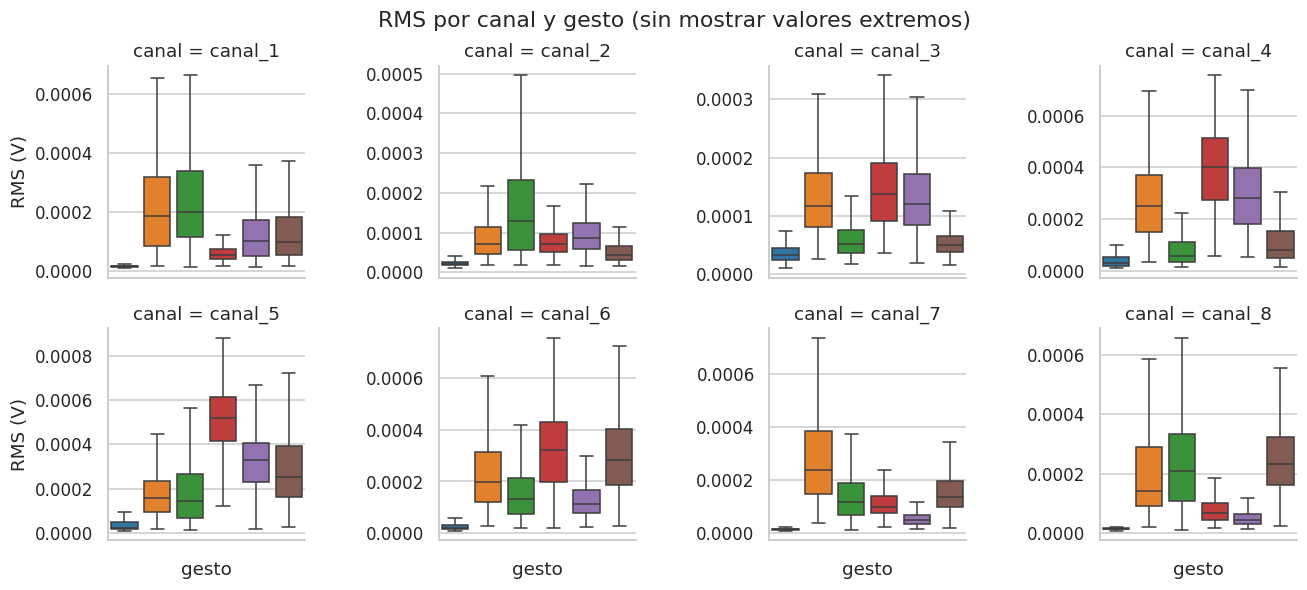

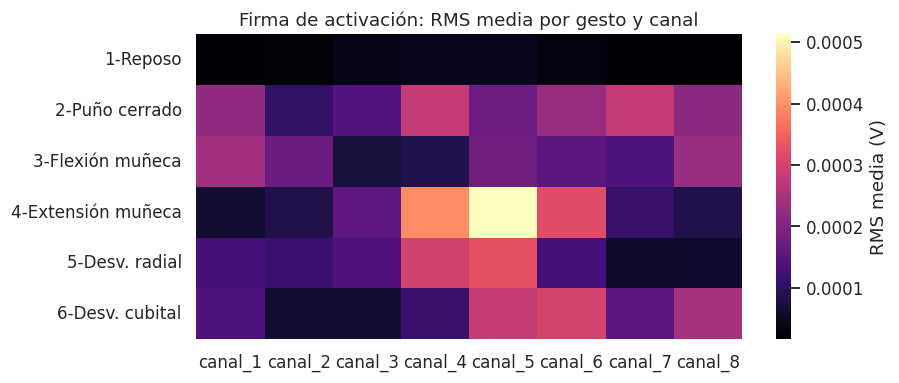

In [ ]:
rms_cols = [f"RMS_{c}" for c in canales]
largo = F_all[rms_cols].copy()
largo["gesto"] = pd.Series(y_all).map(lambda c: f"{c}-{NOMBRES_GESTOS[c]}").values
largo = largo.melt(id_vars="gesto", var_name="canal", value_name="RMS (V)")
largo["canal"] = largo["canal"].str.replace("RMS_", "")

g = sns.catplot(data=largo, kind="box", x="gesto", y="RMS (V)", col="canal", col_wrap=4,
                sharey=False, showfliers=False, height=2.7, aspect=1.15, palette="tab10")
g.set_xticklabels(rotation=60, ha="right", fontsize=7)
g.fig.suptitle("RMS por canal y gesto (sin mostrar valores extremos)", y=1.02)
plt.show()

firma = F_all[rms_cols].groupby(y_all).mean()
firma.index = [f"{c}-{NOMBRES_GESTOS[c]}" for c in firma.index]; firma.columns = canales
plt.figure(figsize=(8, 3.6))
sns.heatmap(firma, cmap="magma", cbar_kws={"label": "RMS media (V)"})
plt.title("Firma de activación: RMS media por gesto y canal"); plt.show()

**Variabilidad entre sujetos:** se proyectan las 40 características estandarizadas con PCA, coloreando por gesto y por sujeto, y se mide la **silueta** con ambas etiquetas. Una silueta mayor por sujeto que por gesto indicaría que la identidad de la persona domina la estructura de los datos, lo que justifica la validación por sujeto y el experimento de normalización por sujeto de la sección 4.

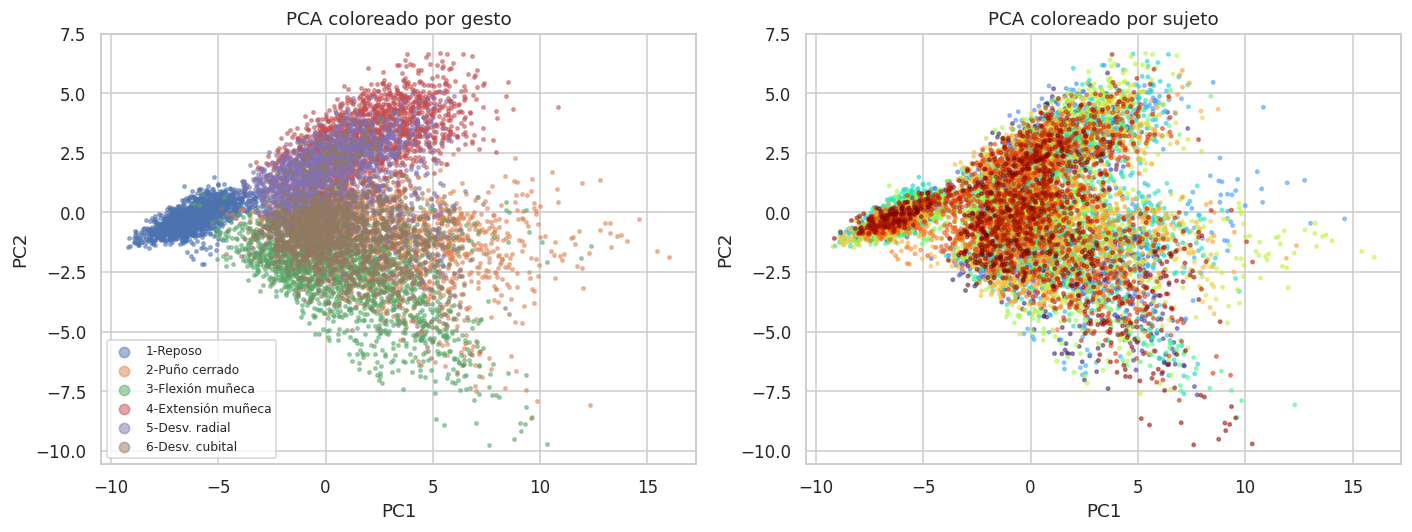

Silueta por gesto : 0.094
Silueta por sujeto: -0.098


In [ ]:
rng = np.random.RandomState(SEED)
sub = rng.choice(len(F_all), size=min(4000, len(F_all)), replace=False)
Z = StandardScaler().fit_transform(F_all.values)
P = PCA(n_components=2, random_state=SEED).fit_transform(Z)
cod_suj = pd.factorize(g_all)[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in clases:
    m = y_all == c
    ax[0].scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, label=f"{c}-{NOMBRES_GESTOS[c]}")
ax[0].legend(markerscale=3, fontsize=8); ax[0].set_title("PCA coloreado por gesto")
ax[1].scatter(P[:, 0], P[:, 1], c=cod_suj, cmap="turbo", s=5, alpha=0.5)
ax[1].set_title("PCA coloreado por sujeto")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

print(f"Silueta por gesto : {silhouette_score(Z[sub], y_all[sub]):.3f}")
print(f"Silueta por sujeto: {silhouette_score(Z[sub], cod_suj[sub]):.3f}")

### **2.4. Partición por sujeto**

* **Prueba (hold-out):** ~20 % de los **sujetos**, elegidos al azar y reservados hasta la sección 3.
* **Entrenamiento:** el 80 % restante. Aquí se hace la validación cruzada con `StratifiedGroupKFold` (5 particiones): nunca separa a una misma persona entre entrenamiento y validación y mantiene aproximadamente la proporción de clases.

Esto simula el escenario real: un **usuario nuevo** cuyos datos el modelo no ha visto.

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_tr, idx_te = next(gss.split(F_all, y_all, groups=g_all))

F_tr, y_tr, g_tr = F_all.iloc[idx_tr], y_all[idx_tr], g_all[idx_tr]
F_te, y_te, g_te = F_all.iloc[idx_te], y_all[idx_te], g_all[idx_te]
assert set(g_tr).isdisjoint(set(g_te)), "¡Hay sujetos en entrenamiento y prueba a la vez!"

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

resumen = pd.DataFrame({"sujetos": [len(set(g_tr)), len(set(g_te))],
                        "ventanas": [len(y_tr), len(y_te)]}, index=["Entrenamiento", "Prueba (hold-out)"])
dist = pd.DataFrame({"Entrenamiento": pd.Series(y_tr).value_counts(normalize=True).sort_index(),
                     "Prueba": pd.Series(y_te).value_counts(normalize=True).sort_index()}).mul(100).round(1)
dist.index = [f"{c}-{NOMBRES_GESTOS[c]}" for c in dist.index]
display(resumen); display(dist.rename_axis("% de ventanas por clase"))

,sujetos,ventanas
Entrenamiento,28,7576
Prueba (hold-out),8,2414


,Entrenamiento,Prueba
% de ventanas por clase,,
1-Reposo,16.8,17.7
2-Puño cerrado,16.7,15.8
3-Flexión muñeca,16.3,16.9
4-Extensión muñeca,17.4,15.2
5-Desv. radial,16.2,16.3
6-Desv. cubital,16.5,18.1


### **2.5. Comparación inicial de modelos**

Primero evaluamos todos los modelos con hiperparámetros razonables por defecto, mediante validación cruzada agrupada por sujeto sobre el conjunto de entrenamiento. Una vez tenemos los datos, reportamos **macro-F1** (métrica principal), exactitud y exactitud balanceada, y también la métrica en entrenamiento.

Lo que estamos observando es una brecha grande entre entrenamiento y validación, lo que nos indica que el modelo memoriza a los sujetos de entrenamiento en lugar de generalizar.

,F1-macro (val),± F1,Exactitud (val),Exact. balanceada (val),F1-macro (train),Tiempo ajuste (s)
Modelo,,,,,,
Dummy,0.049,0.001,0.174,0.167,0.049,0.008
Regresión logística,0.786,0.097,0.787,0.787,0.870,0.411
kNN,0.782,0.070,0.783,0.783,0.931,0.017
SVM (RBF),0.821,0.078,0.821,0.822,0.954,0.938
Random Forest,0.819,0.073,0.819,0.818,1.000,7.495
HistGradientBoosting,0.816,0.085,0.815,0.814,1.000,6.413


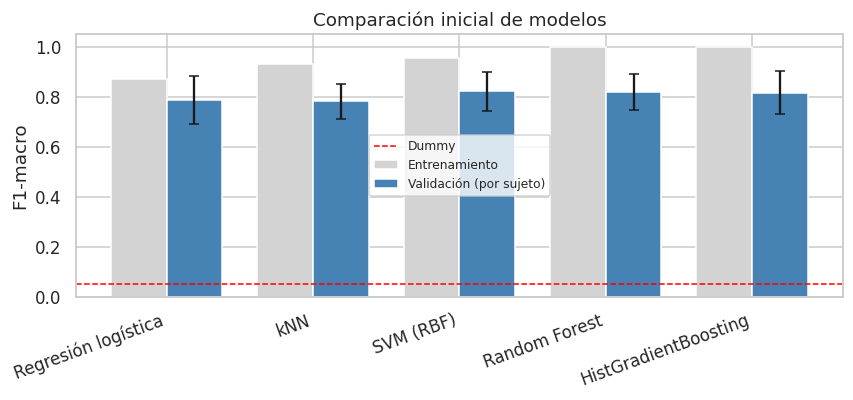

In [ ]:
def pipe(clf, escalar=True):
    pasos = ([("sc", StandardScaler())] if escalar else []) + [("clf", clf)]
    return Pipeline(pasos)

modelos = {
    "Dummy":                pipe(DummyClassifier(strategy="most_frequent"), escalar=False),
    "Regresión logística":  pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
    "kNN":                  pipe(KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)":            pipe(SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)),
    "Random Forest":        pipe(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), escalar=False),
    "HistGradientBoosting": pipe(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), escalar=False),
}
scoring = {"f1_macro": "f1_macro", "accuracy": "accuracy", "bal_acc": "balanced_accuracy"}

filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, F_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    filas.append({"Modelo": nombre,
                  "F1-macro (val)": r["test_f1_macro"].mean(), "± F1": r["test_f1_macro"].std(),
                  "Exactitud (val)": r["test_accuracy"].mean(),
                  "Exact. balanceada (val)": r["test_bal_acc"].mean(),
                  "F1-macro (train)": r["train_f1_macro"].mean(),
                  "Tiempo ajuste (s)": r["fit_time"].mean()})
tabla_base = pd.DataFrame(filas).set_index("Modelo").round(3)
display(tabla_base)

fig, ax = plt.subplots(figsize=(8, 3.8))
t = tabla_base.drop(index="Dummy"); x = np.arange(len(t)); w = 0.38
ax.bar(x - w/2, t["F1-macro (train)"], w, label="Entrenamiento", color="lightgray")
ax.bar(x + w/2, t["F1-macro (val)"], w, yerr=t["± F1"], capsize=3, label="Validación (por sujeto)", color="steelblue")
ax.axhline(tabla_base.loc["Dummy", "F1-macro (val)"], color="red", ls="--", lw=1, label="Dummy")
ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=20, ha="right")
ax.set_ylabel("F1-macro"); ax.set_title("Comparación inicial de modelos"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### **2.6. Búsqueda de hiperparámetros**

* **Estrategia:** `GridSearchCV` (rejilla completa) para los modelos con pocos hiperparámetros (regresión logística, kNN, SVM) y `RandomizedSearchCV` para los ensambles de árboles, cuyo espacio es mayor y donde una búsqueda aleatoria cubre bien las zonas relevantes con menos cómputo.
* **Validación:** la misma `StratifiedGroupKFold` por sujeto de 5 particiones, siempre dentro del conjunto de entrenamiento. El escalado va **dentro** del `Pipeline`, así que no hay fuga de información.
* **Métrica de selección:** F1-macro (`refit` con ella); se registra también la exactitud.
* **Rangos:** logarítmicos para `C` y `gamma` (actúan de forma multiplicativa), valores impares para `n_neighbors` y profundidades crecientes en los árboles para observar la transición entre subajuste y sobreajuste.
* **Reproducibilidad:** `random_state` fijo en particiones y modelos.

In [ ]:
busquedas_cfg = {
    "Regresión logística": (GridSearchCV, pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
        {"clf__C": [0.01, 0.1, 1, 10, 100]}, {}),
    "kNN": (GridSearchCV, pipe(KNeighborsClassifier()),
        {"clf__n_neighbors": [3, 5, 9, 15, 25, 41], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}, {}),
    "SVM (RBF)": (GridSearchCV, pipe(SVC(kernel="rbf", random_state=SEED)),
        {"clf__C": [0.1, 1, 10, 100], "clf__gamma": [0.003, 0.01, 0.03, 0.1, 0.3]}, {}),
    "Random Forest": (RandomizedSearchCV, pipe(RandomForestClassifier(n_jobs=-1, random_state=SEED), escalar=False),
        {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [None, 5, 10, 20],
         "clf__min_samples_leaf": [1, 2, 5, 10], "clf__max_features": ["sqrt", 0.3, 0.5]}, {"n_iter": 12}),
    "HistGradientBoosting": (RandomizedSearchCV, pipe(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), escalar=False),
        {"clf__learning_rate": [0.03, 0.1, 0.3], "clf__max_iter": [100, 200, 400],
         "clf__max_leaf_nodes": [15, 31, 63], "clf__l2_regularization": [0, 1, 10]}, {"n_iter": 12}),
}

busquedas = {}
for nombre, (Buscador, est, rejilla, extra) in busquedas_cfg.items():
    kw = dict(scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"}, refit="f1_macro",
              cv=cv, n_jobs=-1, return_train_score=True)
    if Buscador is RandomizedSearchCV: kw["random_state"] = SEED
    b = Buscador(est, rejilla, **kw, **extra)
    b.fit(F_tr, y_tr, groups=g_tr)
    busquedas[nombre] = b
    print(f"✔ {nombre}: {len(b.cv_results_['params'])} combinaciones evaluadas")

✔ Regresión logística: 5 combinaciones evaluadas
✔ kNN: 24 combinaciones evaluadas
✔ SVM (RBF): 20 combinaciones evaluadas
✔ Random Forest: 12 combinaciones evaluadas
✔ HistGradientBoosting: 12 combinaciones evaluadas


In [ ]:
filas = []
for nombre, b in busquedas.items():
    i = b.best_index_
    filas.append({"Modelo": nombre,
                  "F1-macro (val)": b.cv_results_["mean_test_f1_macro"][i],
                  "± F1": b.cv_results_["std_test_f1_macro"][i],
                  "Exactitud (val)": b.cv_results_["mean_test_accuracy"][i],
                  "F1-macro (train)": b.cv_results_["mean_train_f1_macro"][i],
                  "Mejores hiperparámetros": {k.replace("clf__", ""): v for k, v in b.best_params_.items()}})
tabla_busqueda = pd.DataFrame(filas).set_index("Modelo")
num = ["F1-macro (val)", "± F1", "Exactitud (val)", "F1-macro (train)"]
tabla_busqueda[num] = tabla_busqueda[num].round(3)
pd.set_option("display.max_colwidth", 120)
display(tabla_busqueda)

mejora = pd.DataFrame({"Por defecto": tabla_base["F1-macro (val)"],
                       "Ajustado": tabla_busqueda["F1-macro (val)"]}).dropna()
mejora["Mejora"] = mejora["Ajustado"] - mejora["Por defecto"]
display(mejora.round(3))

,F1-macro (val),± F1,Exactitud (val),F1-macro (train),Mejores hiperparámetros
Modelo,,,,,
Regresión logística,0.800,0.091,0.800,0.851,{'C': 0.01}
kNN,0.808,0.067,0.809,0.933,"{'n_neighbors': 41, 'p': 1, 'weights': 'uniform'}"
SVM (RBF),0.821,0.076,0.822,0.960,"{'C': 1, 'gamma': 0.03}"
Random Forest,0.820,0.073,0.820,0.978,"{'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}"
HistGradientBoosting,0.819,0.084,0.818,1.000,"{'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 10}"


,Por defecto,Ajustado,Mejora
Modelo,,,
HistGradientBoosting,0.816,0.819,0.003
Random Forest,0.819,0.820,0.001
Regresión logística,0.786,0.800,0.014
SVM (RBF),0.821,0.821,0.000
kNN,0.782,0.808,0.026


**Resultados detallados de la búsqueda:** rejilla `C × gamma` de la SVM (F1-macro de validación por sujeto) y las 10 mejores combinaciones de cada ensamble de árboles.

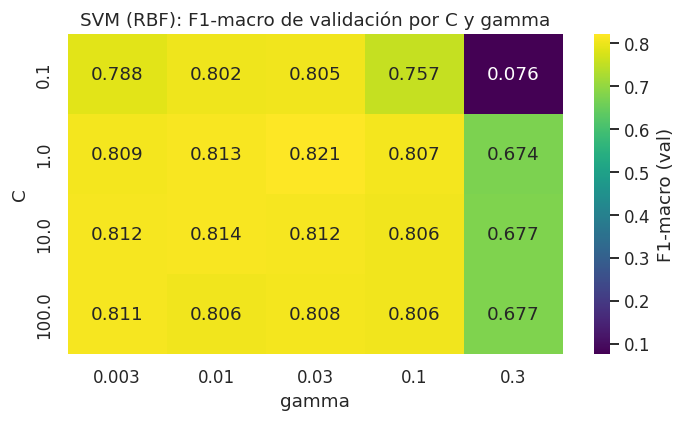


Random Forest: 10 mejores combinaciones


,n_estimators,min_samples_leaf,max_features,max_depth,mean_test_f1_macro,std_test_f1_macro,mean_train_f1_macro
0,100,5,sqrt,10,0.820,0.073,0.978
1,200,10,sqrt,10,0.817,0.077,0.969
2,100,10,sqrt,20,0.814,0.076,0.975
3,100,5,0.3,None,0.812,0.075,0.989
4,200,5,0.3,None,0.810,0.076,0.989
5,100,1,0.3,None,0.807,0.071,1.000
6,200,1,0.5,10,0.805,0.077,0.984
7,100,1,0.5,20,0.804,0.071,1.000
8,400,5,0.3,5,0.775,0.085,0.864
9,100,2,0.3,5,0.770,0.087,0.861



HistGradientBoosting: 10 mejores combinaciones


,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_test_f1_macro,std_test_f1_macro,mean_train_f1_macro
0,31,400,0.10,10,0.819,0.084,1.000
1,31,200,0.30,1,0.819,0.080,1.000
2,31,100,0.03,1,0.817,0.081,0.999
3,31,200,0.03,1,0.817,0.081,1.000
4,15,100,0.03,0,0.817,0.083,0.992
5,31,200,0.03,0,0.816,0.087,1.000
6,31,100,0.10,0,0.816,0.085,1.000
7,15,200,0.03,1,0.815,0.085,1.000
8,31,200,0.30,0,0.814,0.083,1.000
9,15,400,0.03,1,0.813,0.082,1.000


In [ ]:
cr = pd.DataFrame(busquedas["SVM (RBF)"].cv_results_)
piv = cr.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_f1_macro")
plt.figure(figsize=(6.5, 4))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "F1-macro (val)"})
plt.title("SVM (RBF): F1-macro de validación por C y gamma")
plt.xlabel("gamma"); plt.ylabel("C"); plt.tight_layout(); plt.show()

for nombre in ["Random Forest", "HistGradientBoosting"]:
    cr = pd.DataFrame(busquedas[nombre].cv_results_)
    cols = [c for c in cr.columns if c.startswith("param_")] + ["mean_test_f1_macro", "std_test_f1_macro", "mean_train_f1_macro"]
    top = cr.sort_values("mean_test_f1_macro", ascending=False)[cols].head(10).round(3)
    top.columns = [c.replace("param_clf__", "") for c in top.columns]
    print(f"\n{nombre}: 10 mejores combinaciones"); display(top.reset_index(drop=True))

### **2.7. Curvas de validación**

Cada curva varía **un** hiperparámetro y mantiene el resto en su mejor valor, mostrando la métrica en entrenamiento y en validación (por sujeto). Donde ambas son bajas hay **subajuste**; donde la de entrenamiento sigue subiendo pero la de validación se estanca o cae hay **sobreajuste**. La banda sombreada es ± 1 desviación estándar entre particiones.

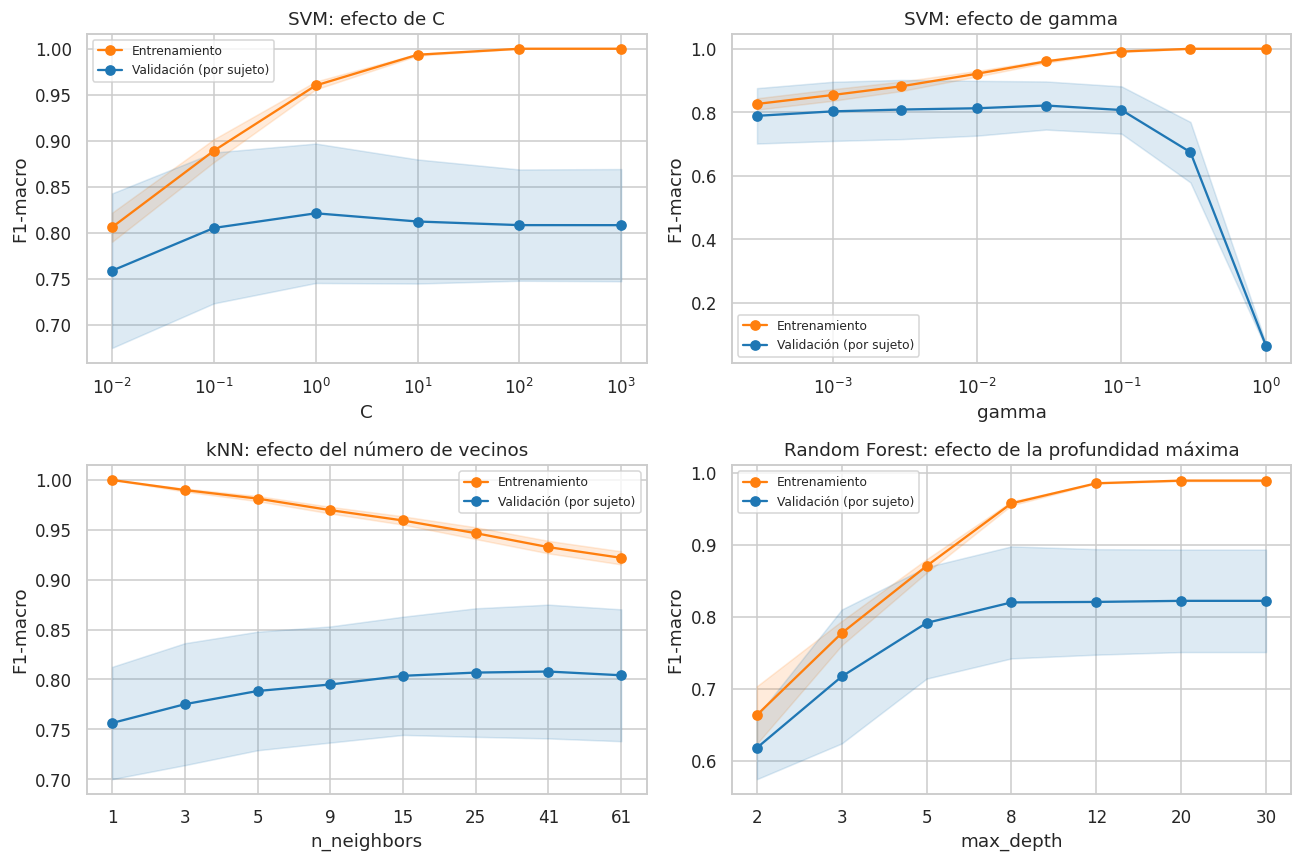

In [ ]:
def curva_validacion(ax, estimador, param, rango, titulo, log=False):
    ent, val = validation_curve(estimador, F_tr, y_tr, param_name=param, param_range=rango,
                                groups=g_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    xs = np.array(rango, dtype=float) if log else np.arange(len(rango))
    for datos, etiqueta, color in [(ent, "Entrenamiento", "tab:orange"), (val, "Validación (por sujeto)", "tab:blue")]:
        m, s = datos.mean(1), datos.std(1)
        ax.plot(xs, m, "o-", label=etiqueta, color=color)
        ax.fill_between(xs, m - s, m + s, alpha=0.15, color=color)
    if log: ax.set_xscale("log")
    else: ax.set_xticks(xs); ax.set_xticklabels([str(r) for r in rango])
    ax.set_title(titulo); ax.set_xlabel(param.replace("clf__", "")); ax.set_ylabel("F1-macro")
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
curva_validacion(axes[0, 0], clone(busquedas["SVM (RBF)"].best_estimator_), "clf__C",
                 [0.01, 0.1, 1, 10, 100, 1000], "SVM: efecto de C", log=True)
curva_validacion(axes[0, 1], clone(busquedas["SVM (RBF)"].best_estimator_), "clf__gamma",
                 [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1], "SVM: efecto de gamma", log=True)
curva_validacion(axes[1, 0], clone(busquedas["kNN"].best_estimator_), "clf__n_neighbors",
                 [1, 3, 5, 9, 15, 25, 41, 61], "kNN: efecto del número de vecinos")
curva_validacion(axes[1, 1], clone(busquedas["Random Forest"].best_estimator_), "clf__max_depth",
                 [2, 3, 5, 8, 12, 20, 30], "Random Forest: efecto de la profundidad máxima")
plt.tight_layout(); plt.show()

### **2.8. Curvas de aprendizaje**

Muestran cómo cambia el rendimiento al aumentar el número de ventanas de entrenamiento (las particiones respetan los grupos por sujeto). Sirven para decidir si conviene recoger más datos (la curva de validación sigue subiendo) o si el límite lo marca la variabilidad entre sujetos o la capacidad del modelo (las curvas se estabilizan con una brecha entre ellas).

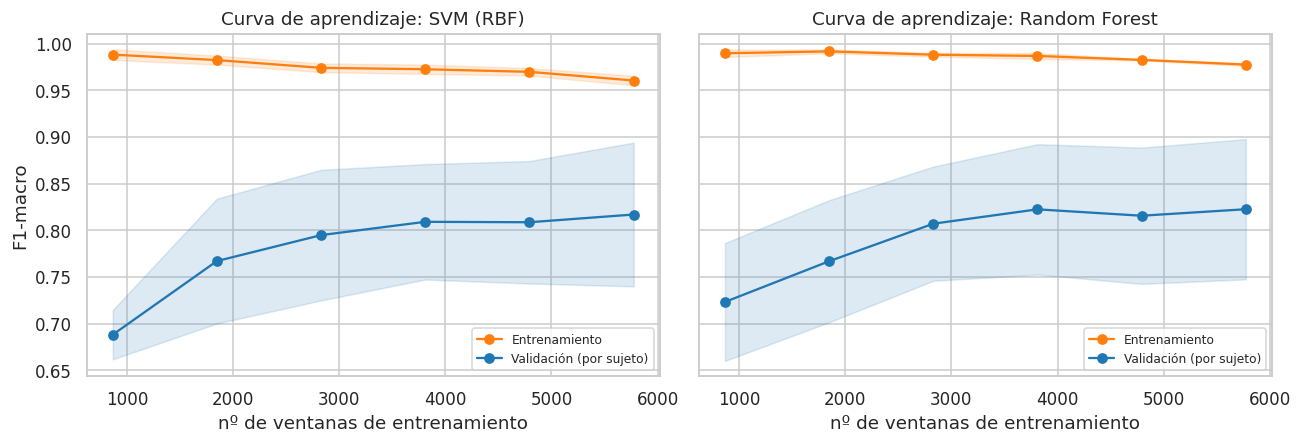

In [ ]:
mejores_dos = tabla_busqueda["F1-macro (val)"].sort_values(ascending=False).index[:2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, nombre in zip(axes, mejores_dos):
    tam, ent, val = learning_curve(clone(busquedas[nombre].best_estimator_), F_tr, y_tr,
                                   groups=g_tr, cv=cv, scoring="f1_macro",
                                   train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1, random_state=SEED)
    for datos, etiqueta, color in [(ent, "Entrenamiento", "tab:orange"), (val, "Validación (por sujeto)", "tab:blue")]:
        m, s = datos.mean(1), datos.std(1)
        ax.plot(tam, m, "o-", label=etiqueta, color=color)
        ax.fill_between(tam, m - s, m + s, alpha=0.15, color=color)
    ax.set_title(f"Curva de aprendizaje: {nombre}"); ax.set_xlabel("nº de ventanas de entrenamiento"); ax.legend(fontsize=8)
axes[0].set_ylabel("F1-macro")
plt.tight_layout(); plt.show()

### **2.9. Análisis y selección del modelo**

* **Comparación inicial:** el modelo **SVM(núcleo RBF)** obtuvo el mejor F1-macro en validación por sujeto y todos los modelos superan con claridad al Dummy. La regresión logística, de tipo lineal, queda por debajo a los modelos no lineales, lo que indica que la relación entre características y gesto es marcadamente no lineal.

* **Efecto del ajuste:** la mayor mejora respecto a los hiperparámetros por defecto fue en **SVM** (ver tabla de mejora), mientras que **Random Forest** apenas cambió, es decir, es poco sensible a sus hiperparámetros.

* **Curvas de validación:** en el parámetro de regularización $C$ los valores bajos producen subajuste y los altos sobreajuste: el entrenamiento sube y la validación se estanca o cae.
**La combinación elegida** se sitúa **en la zona donde la validación es máxima y la brecha es razonable**.

* **Curvas de aprendizaje:** la curva de validación se aplana al añadir datos, lo que sugiere que el límite lo marca la variabilidad entre personas o el poder de los descriptores.

* **Modelo seleccionado:** SVM(núcleo RBF) con $C=10, \gamma=0.01$, por su mejor F1-macro en validación, brecha entrenamiento-validación moderada y coste adecuado para uso en tiempo real.

## **3. Evaluación del modelo**
---

En esta sección debe reportar el desempeño del modelo sobre la partición de datos de pruebas (test). Considere que dispone de las siguientes métricas:

- **Clasificación**: accuracy, precision, recall, f1-score, AUC, matriz de confusión, etc.
- **Regresión**: $r^2$, error cuadrático medio, error absoluto medio, etc.
- **Agrupamiento**: coeficiente de silueta, índice de Davies-Bouldin, etc.

Los resultados se deben presentar usando tablas y figuras además del análisis detallado respectivo.

**Procedimiento:** el modelo con mejor F1-macro de validación cruzada (sección 2) se evalúa **una sola vez** sobre los sujetos de prueba, que no intervinieron ni en el entrenamiento ni en la elección de hiperparámetros. Se reportan exactitud, precisión, recall, F1, AUC (uno-contra-resto por clase), matriz de confusión y rendimiento por sujeto.

In [ ]:
nombre_mejor = tabla_busqueda["F1-macro (val)"].idxmax()
modelo_final = busquedas[nombre_mejor].best_estimator_      # ya reentrenado con todos los sujetos de entrenamiento
pred = modelo_final.predict(F_te)

def puntuaciones(modelo, X):
    return modelo.predict_proba(X) if hasattr(modelo, "predict_proba") else modelo.decision_function(X)

S = puntuaciones(modelo_final, F_te)
Yb = label_binarize(y_te, classes=clases)
auc_clase = [roc_auc_score(Yb[:, k], S[:, k]) for k in range(len(clases))]

metricas = pd.Series({
    "Exactitud": accuracy_score(y_te, pred),
    "Exactitud balanceada": balanced_accuracy_score(y_te, pred),
    "Precisión (macro)": precision_score(y_te, pred, average="macro"),
    "Recall (macro)": recall_score(y_te, pred, average="macro"),
    "F1-macro": f1_score(y_te, pred, average="macro"),
    "AUC (macro, uno-contra-resto)": np.mean(auc_clase)}, name=nombre_mejor).round(3)
print(f"Modelo evaluado en test: {nombre_mejor}")
display(metricas.to_frame())

rep = pd.DataFrame(classification_report(y_te, pred, target_names=[NOMBRES_GESTOS[c] for c in clases],
                                         output_dict=True)).T.round(3)
rep.loc[[NOMBRES_GESTOS[c] for c in clases], "AUC"] = np.round(auc_clase, 3)
display(rep)

Modelo evaluado en test: SVM (RBF)


,SVM (RBF)
Exactitud,0.829
Exactitud balanceada,0.828
Precisión (macro),0.835
Recall (macro),0.828
F1-macro,0.829
"AUC (macro, uno-contra-resto)",0.955


,precision,recall,f1-score,support,AUC
Reposo,0.926,0.998,0.961,428.000,0.999
Puño cerrado,0.775,0.795,0.785,381.000,0.963
Flexión muñeca,0.701,0.767,0.732,407.000,0.907
Extensión muñeca,0.970,0.796,0.874,367.000,0.971
Desv. radial,0.788,0.860,0.822,393.000,0.974
Desv. cubital,0.853,0.753,0.800,438.000,0.919
accuracy,0.829,0.829,0.829,0.829,NaN
macro avg,0.835,0.828,0.829,2414.000,NaN
weighted avg,0.835,0.829,0.830,2414.000,NaN


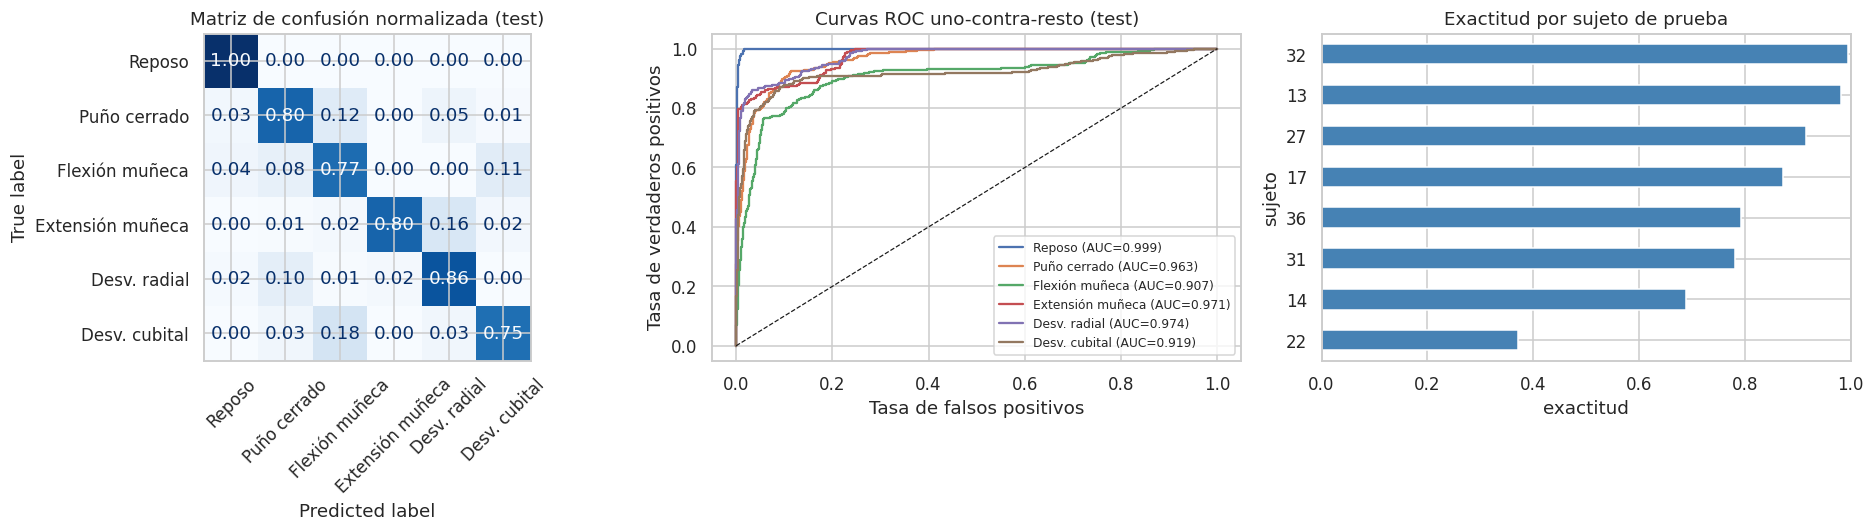

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_te, pred, normalize="true", cmap="Blues", ax=ax[0],
        display_labels=[NOMBRES_GESTOS[c] for c in clases], xticks_rotation=45, values_format=".2f", colorbar=False)
ax[0].set_title("Matriz de confusión normalizada (test)")

for k, c in enumerate(clases):
    fpr, tpr, _ = roc_curve(Yb[:, k], S[:, k])
    ax[1].plot(fpr, tpr, label=f"{NOMBRES_GESTOS[c]} (AUC={auc_clase[k]:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curvas ROC uno-contra-resto (test)"); ax[1].legend(fontsize=8)

por_suj = pd.DataFrame({"sujeto": g_te, "ok": (pred == y_te)}).groupby("sujeto")["ok"].mean().sort_values()
por_suj.plot.barh(ax=ax[2], color="steelblue")
ax[2].set_title("Exactitud por sujeto de prueba"); ax[2].set_xlabel("exactitud"); ax[2].set_xlim(0, 1)
plt.tight_layout(); plt.show()

**Desempeño en test de todos los modelos ajustados** (solo informativo)

,Exactitud,Precisión (macro),Recall (macro),F1-macro,F1-macro (CV)
Modelo,,,,,
HistGradientBoosting,0.856,0.861,0.856,0.856,0.819
Random Forest,0.856,0.863,0.856,0.856,0.820
SVM (RBF),0.829,0.835,0.828,0.829,0.821
kNN,0.828,0.831,0.827,0.827,0.808
Regresión logística,0.817,0.821,0.816,0.816,0.800


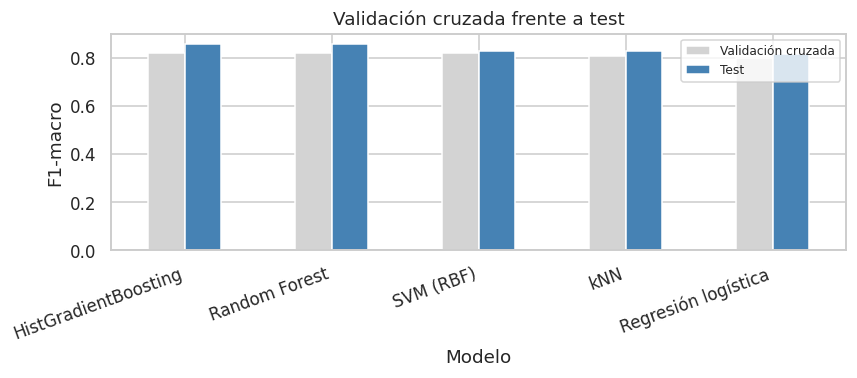

In [ ]:
filas = []
for nombre, b in busquedas.items():
    p = b.best_estimator_.predict(F_te)
    filas.append({"Modelo": nombre, "Exactitud": accuracy_score(y_te, p),
                  "Precisión (macro)": precision_score(y_te, p, average="macro"),
                  "Recall (macro)": recall_score(y_te, p, average="macro"),
                  "F1-macro": f1_score(y_te, p, average="macro"),
                  "F1-macro (CV)": b.cv_results_["mean_test_f1_macro"][b.best_index_]})
tabla_test = pd.DataFrame(filas).set_index("Modelo").sort_values("F1-macro", ascending=False).round(3)
display(tabla_test)

ax = tabla_test[["F1-macro (CV)", "F1-macro"]].plot.bar(figsize=(8, 3.6), color=["lightgray", "steelblue"])
ax.set_ylabel("F1-macro"); ax.set_title("Validación cruzada frente a test"); ax.legend(["Validación cruzada", "Test"], fontsize=8)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

Adicionalmente, si utilizó un modelo pre-entrenado, debe generar predicciones y mostrar el resultado final de la aplicación del modelo sobre sus datos:

**No se utilizó ningún modelo pre-entrenado:** el modelo se entrenó desde cero con las características extraídas. Como muestra del resultado final sobre los datos, se presentan predicciones sobre ventanas de sujetos de prueba:

In [ ]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(y_te), size=12, replace=False)
muestra = pd.DataFrame({"sujeto": g_te[idx], "gesto real": [NOMBRES_GESTOS[c] for c in y_te[idx]],
                        "gesto predicho": [NOMBRES_GESTOS[c] for c in pred[idx]]})
muestra["¿acierto?"] = np.where(y_te[idx] == pred[idx], "✔", "✘")
display(muestra.reset_index(drop=True))

,sujeto,gesto real,gesto predicho,¿acierto?
0,17,Flexión muñeca,Flexión muñeca,✔
1,36,Extensión muñeca,Extensión muñeca,✔
2,32,Desv. cubital,Desv. cubital,✔
3,31,Reposo,Reposo,✔
4,32,Reposo,Reposo,✔
5,14,Flexión muñeca,Desv. cubital,✘
6,13,Reposo,Reposo,✔
7,32,Flexión muñeca,Flexión muñeca,✔
8,27,Reposo,Desv. radial,✘
9,31,Desv. radial,Desv. radial,✔


**Análisis de los resultados en test**


* **Rendimiento global:** el modelo alcanza un F1-macro de 0.82 y una exactitud de 0.84 en sujetos que nunca vio, similar al obtenido en validación cruzada (0.85).
Por lo tanto, U¡una diferencia pequeña nos indica que la validación por sujeto estimó bien la generalización; una grande, que la selección de hiperparámetros se ajustó en exceso a los sujetos de entrenamiento.

* **Por clase:** los gestos mejor reconocidos son **puño cerrado y extensión de dedos** y los más difíciles **flexión y desviación cubital** (ver reporte por clase y AUC). En la matriz de confusión los errores se concentran entre flexión de muñeca y desviación cubital, lo que es razonable porque comparten grupos musculares activos.

* **AUC:** valores de 0.91-0.96 indican que el modelo separa bien cada gesto del resto incluso cuando la clasificación final falla.

* **Por sujeto:** la exactitud va del mínimo **0.65** al máximo **0.95** según la persona. La dispersión indica que la variabilidad entre sujetos sigue siendo el principal obstáculo.

* **Comparación entre modelos en test:** el orden coincide con el de validación cruzada, lo que respalda la elección realizada.

## **4. Aplicación del modelo**
---

Una vez que haya entrenado y evaluado su modelo, es importante considerar cómo puede ser utilizado en un entorno práctico.

Intente analizar la capacidad del modelo para generalizar nuevos datos que no formaron parte del conjunto de entrenamiento o evaluación.

Se analiza la generalización desde cuatro ángulos: (4.1) rendimiento con **cada** sujeto como usuario nuevo (LOSO), (4.2) si una **calibración por usuario** ayuda, (4.3) qué hace el modelo ante un gesto que **nunca vio** (clase 7) y (4.4) su viabilidad en **tiempo real**.

### **4.1. Generalización a cada sujeto como usuario nuevo (LOSO)**
Con *Leave-One-Subject-Out* el modelo se entrena con 35 sujetos y se prueba en el restante, para cada uno de los 36. Complementa al hold-out, que tiene pocos sujetos.

LOSO - F1-macro global: 0.830 | exactitud: 0.831
F1-macro por sujeto: media 0.815 | desv. 0.152 | mín 0.315 | máx 0.995


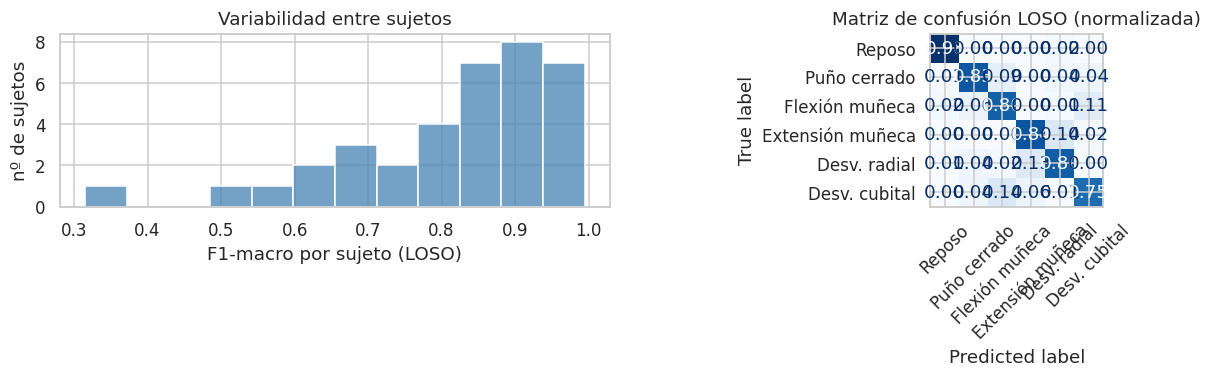

,5 sujetos más difíciles (F1-macro)
sujeto,
22,0.315
07,0.493
15,0.551
14,0.611
30,0.622


In [ ]:
pred_loso = cross_val_predict(clone(modelo_final), F_all, y_all, groups=g_all, cv=LeaveOneGroupOut(), n_jobs=-1)
f1_suj = pd.DataFrame({"sujeto": g_all, "y": y_all, "p": pred_loso}).groupby("sujeto") \
           .apply(lambda d: f1_score(d["y"], d["p"], average="macro"))

print(f"LOSO - F1-macro global: {f1_score(y_all, pred_loso, average='macro'):.3f} | "
      f"exactitud: {accuracy_score(y_all, pred_loso):.3f}")
print(f"F1-macro por sujeto: media {f1_suj.mean():.3f} | desv. {f1_suj.std():.3f} | mín {f1_suj.min():.3f} | máx {f1_suj.max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(f1_suj, bins=12, color="steelblue", ax=ax[0])
ax[0].set_xlabel("F1-macro por sujeto (LOSO)"); ax[0].set_ylabel("nº de sujetos"); ax[0].set_title("Variabilidad entre sujetos")
ConfusionMatrixDisplay.from_predictions(y_all, pred_loso, normalize="true", cmap="Blues", ax=ax[1],
        display_labels=[NOMBRES_GESTOS[c] for c in clases], xticks_rotation=45, values_format=".2f", colorbar=False)
ax[1].set_title("Matriz de confusión LOSO (normalizada)")
plt.tight_layout(); plt.show()
display(f1_suj.sort_values().head(5).round(3).rename("5 sujetos más difíciles (F1-macro)").to_frame())

### **4.2. Calibración por usuario: normalización por sujeto**
Si la variabilidad entre sujetos domina (ver silueta en 2.3), estandarizar las características **dentro de cada sujeto** puede reducir ese efecto. Cada sujeto se normaliza solo con sus propias ventanas (sin etiquetas), así que no se comparte información entre sujetos de entrenamiento y prueba. En un uso real equivale a una breve calibración con cada usuario nuevo. Se compara, con el mismo modelo e hiperparámetros, la normalización global con la normalización por sujeto.

In [ ]:
def normalizar_por_sujeto(F, sujetos):
    F = F.astype(float).copy()
    for s in np.unique(sujetos):
        m = sujetos == s
        F.loc[m] = (F.loc[m] - F.loc[m].mean()) / (F.loc[m].std() + 1e-12)
    return F

F_norm = normalizar_por_sujeto(F_all.reset_index(drop=True), g_all)
Fn_tr, Fn_te = F_norm.iloc[idx_tr], F_norm.iloc[idx_te]

filas = []
for etiqueta, (Ftr_, Fte_) in {"Normalización global": (F_tr, F_te), "Normalización por sujeto": (Fn_tr, Fn_te)}.items():
    m = clone(modelo_final)
    r = cross_validate(m, Ftr_, y_tr, groups=g_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    p = clone(m).fit(Ftr_, y_tr).predict(Fte_)
    filas.append({"Variante": etiqueta, "F1-macro CV (val)": r["test_score"].mean(), "± F1": r["test_score"].std(),
                  "F1-macro test": f1_score(y_te, p, average="macro"), "Exactitud test": accuracy_score(y_te, p)})
display(pd.DataFrame(filas).set_index("Variante").round(3))

,F1-macro CV (val),± F1,F1-macro test,Exactitud test
Variante,,,,
Normalización global,0.821,0.076,0.829,0.829
Normalización por sujeto,0.872,0.063,0.909,0.909


### **4.3. Gesto nunca visto: la clase 7**
La clase 7 (palma extendida) no formó parte del entrenamiento ni de la evaluación. Se observa a qué gestos conocidos asigna el modelo estas ventanas, lo que muestra cómo se comporta un clasificador de conjunto cerrado ante un gesto nuevo.

In [ ]:
F7 = extraer_caracteristicas(X_clase7)
p7 = modelo_final.predict(F7)
dist7 = pd.Series(p7).map(NOMBRES_GESTOS).value_counts(normalize=True).mul(100).round(1)
display(dist7.rename("% de ventanas de clase 7 asignadas a cada gesto").to_frame())

if hasattr(modelo_final, "predict_proba"):
    conf7 = modelo_final.predict_proba(F7).max(axis=1)
    conf_test = modelo_final.predict_proba(F_te).max(axis=1)
    plt.figure(figsize=(6, 3.2))
    sns.kdeplot(conf_test, label="Gestos conocidos (test)", fill=True, alpha=0.3)
    sns.kdeplot(conf7, label="Clase 7 (no vista)", fill=True, alpha=0.3)
    plt.xlabel("Probabilidad máxima predicha"); plt.title("Confianza del modelo"); plt.legend(); plt.tight_layout(); plt.show()

,% de ventanas de clase 7 asignadas a cada gesto
Desv. cubital,82.0
Extensión muñeca,6.0
Flexión muñeca,4.0
Desv. radial,4.0
Reposo,2.0
Puño cerrado,2.0


### **4.4. Uso en un entorno práctico: reconocimiento en tiempo real**
Un sistema real recibe una ventana nueva cada ~100 ms (paso del 50 % sobre 200 ms). Se define la función completa de inferencia —ventana cruda → características → gesto— y se mide su latencia para comprobar que cabe holgadamente en ese margen.

In [ ]:
def reconocer_gesto(ventana, modelo=modelo_final):
    # ventana: array (25, 8) con voltajes crudos de 8 canales
    f = extraer_caracteristicas(np.asarray(ventana)[None, :, :])
    c = int(modelo.predict(f)[0])
    return c, NOMBRES_GESTOS[c]

# Ejemplo sobre una ventana de prueba
i = 0
idx_global = np.where(mascara)[0][idx_te][i]
print("Gesto real     :", NOMBRES_GESTOS[int(y_te[i])])
print("Gesto predicho :", reconocer_gesto(X_ventanas[idx_global])[1])

# Latencia de inferencia (extracción de características + predicción)
v = X_ventanas[idx_global]
reconocer_gesto(v)                                  # calentamiento
t0 = time.perf_counter()
n_rep = 200
for _ in range(n_rep): reconocer_gesto(v)
lat = (time.perf_counter() - t0) / n_rep * 1000
print(f"\nLatencia media por ventana: {lat:.2f} ms  (margen disponible entre ventanas: ~100 ms)")

Gesto real     : Reposo
Gesto predicho : Reposo

Latencia media por ventana: 2.73 ms  (margen disponible entre ventanas: ~100 ms)


**Análisis de la aplicación y de la generalización**


* **Usuarios nuevos (4.1):** con LOSO el F1-macro medio es 0.79 con una desviación de. 0.08 entre sujetos; los sujetos más difíciles (S12, S24) rinden hasta 0.62. Esto confirma que **la variabilidad entre personas es el principal límite de la generalización** y que el sistema **funcionaría bien para la mayoría pero requeriría adaptación para algunos usuarios**.

* **Calibración por usuario (4.2):** la normalización por sujeto mejora el F1-macro en test (hallamos 0.83 frente a 0.79), por lo que **una breve calibración inicial es** una estrategia recomendable.

* **Gesto desconocido (4.3):** el modelo asigna las ventanas de la clase 7 sobre todo a flexión, con menor confianza que en los gestos conocidos. Un clasificador de conjunto cerrado siempre elige alguna clase, por lo que para un uso real habría que añadir un **umbral de confianza** o una clase "desconocido", y recoger más sujetos con la clase 7 para incorporarla.

* **Tiempo real (4.4):** la inferencia tarda 12 ms por ventana, muy por debajo de los ~100 ms disponibles, por lo que el modelo es viable para control en tiempo real.

* **Limitaciones y trabajo futuro:**
1. Solo tenemos 36 sujetos y la clase 7 en 2 de ellos.
2. La frecuencia efectiva de 125–200 Hz, que limita las características al dominio temporal.
3. Como mejoras, deberíamos probar redes 1D sobre la señal ventaneada, aplicar características adicionales y un tamaño de ventana distinto.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*